# 09 · O caminho do 2º turno de 2026 (série G)

**Análise sobre a etapa `segundo_turno` do pipeline** (`src/kingsrace/models/segundo_turno.py`), que
calcula as tabelas e registra as métricas e os gráficos da série G (D12). O registro está em
`docs/hipoteses.md` ("Série G") e o plano em `docs/plano_segundo_turno.md`. Este notebook só lê o
que a etapa gravou e olha os resultados por outros ângulos: heterogeneidade por UF, os municípios
que mais pesam e as checagens.

- **G1** aritmética: quanto cada grupo do 1º turno precisa render;
- **G2** matriz de transição 1º → 2º turno de 2022 por seção (inferência ecológica) e os cenários para 2026;
- **G3/G3b** comparecimento: reserva, votantes perdidos e a base que falta sem governador em disputa;
- **G4** ex-eleitores (LMDI 2º turno 2022 → 1º turno 2026);
- **G5** que tipo de lugar se moveu entre os turnos (exploratória).

In [1]:
import json

import altair as alt
import polars as pl

from kingsrace import paths, resultados
from kingsrace.viz import tema  # noqa: F401  (registra e ativa o tema do projeto)
from kingsrace.viz.tema import DIVERGENTE, SERIES, TINTA

resultados.configura_altair()
live = resultados.abre("09_segundo_turno")

T = paths.PROCESSED / "segundo_turno"
m = json.loads((paths.ROOT / "resultados" / "segundo_turno" / "metrics.json").read_text())
matriz = pl.read_parquet(T / "transicao_2022.parquet")
replicas = pl.read_parquet(T / "transicao_2022_replicas.parquet")
estoques = pl.read_parquet(T / "estoques_2026.parquet")
cenarios = pl.read_parquet(T / "cenarios_2026.parquet")
efeito = pl.read_parquet(T / "efeito_por_origem_2026.parquet")
reserva_mun = pl.read_parquet(T / "reserva_municipio.parquet")
reserva_loc = pl.read_parquet(T / "reserva_local.parquet")
ex = pl.read_parquet(T / "ex_eleitores_amc.parquet")
governador = pl.read_parquet(T / "governador_2t.parquet")
municipios = pl.read_parquet(paths.PROCESSED / "municipios.parquet").select("cd_ibge", "nome")

## G1 · O ponto de partida

Diferença no 1º turno de 2026 (Flávio − Lula, com o exterior) e o que cada estoque precisaria render,
sozinho, para fechá-la. "Taxa necessária" é o saldo Lula − Flávio por eleitor do grupo.

In [2]:
g1 = m["G1"]
(
    pl.DataFrame(
        [
            {
                "grupo": k,
                "milhões": v,
                "taxa necessária (pp)": 100 * g1["taxa_necessaria"].get(k, float("nan")),
            }
            for k, v in g1["estoques_mi"].items()
            if k in ("eliminados", "abst", "bn")
        ]
    ).with_columns(pl.col("milhões", "taxa necessária (pp)").round(2)),
    round(g1["diferenca_mi"], 3),
)

(shape: (3, 3)
 ┌────────────┬─────────┬──────────────────────┐
 │ grupo      ┆ milhões ┆ taxa necessária (pp) │
 │ ---        ┆ ---     ┆ ---                  │
 │ str        ┆ f64     ┆ f64                  │
 ╞════════════╪═════════╪══════════════════════╡
 │ bn         ┆ 5.96    ┆ 37.31                │
 │ abst       ┆ 32.89   ┆ 6.76                 │
 │ eliminados ┆ 9.09    ┆ 23.96                │
 └────────────┴─────────┴──────────────────────┘,
 2.225)

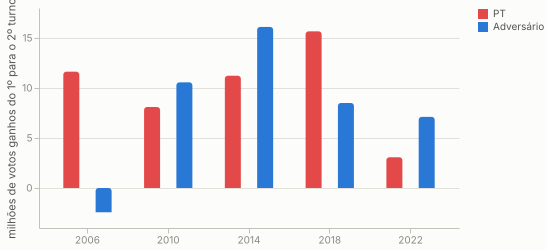

In [3]:
entre = pl.DataFrame([{"ano": a, **v} for a, v in g1["entre_turnos"].items()]).unpivot(
    index="ano", on=["pt_mi", "adv_mi"], variable_name="lado", value_name="mi"
)
resultados.grafico(
    live,
    "G1_entre_turnos",
    alt.Chart(
        entre.with_columns(pl.col("lado").replace_strict({"pt_mi": "PT", "adv_mi": "Adversário"}))
    )
    .mark_bar(cornerRadiusEnd=3, size=16)
    .encode(
        x=alt.X("ano:N", title=None, axis=alt.Axis(labelAngle=0)),
        xOffset="lado:N",
        y=alt.Y("mi:Q", title="milhões de votos ganhos do 1º para o 2º turno"),
        color=alt.Color(
            "lado:N",
            scale=alt.Scale(
                domain=["PT", "Adversário"], range=[DIVERGENTE["pt"], DIVERGENTE["adversario"]]
            ),
            title=None,
        ),
        tooltip=["ano", "lado", alt.Tooltip("mi:Q", format="+.2f")],
    )
    .properties(width=420, height=220),
)

**O que observar:** em 2022 o adversário ganhou mais que o dobro de Lula entre os turnos; em 2006 o
adversário perdeu votos. 2026 começa com Lula atrás.

## G2 · A matriz de 2022 e os cenários

A matriz nacional (média das UFs ponderada pelos votos de cada origem), com o IC do bootstrap de
municípios. Checagem registrada: retenção dos finalistas acima de 0,9.

In [4]:
br = matriz.filter(pl.col("uf") == "BR")
(
    br.with_columns(
        pl.format("{} ({}–{})", *(pl.col(c).round(3) for c in ("b", "ic_inf", "ic_sup"))).alias("v")
    ).pivot(on="destino", index="origem", values="v"),
    m["G2"]["validacao"],
)

(shape: (8, 5)
 ┌──────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┐
 │ origem   ┆ pt                  ┆ adv                 ┆ bn                  ┆ abst                │
 │ ---      ┆ ---                 ┆ ---                 ┆ ---                 ┆ ---                 │
 │ str      ┆ str                 ┆ str                 ┆ str                 ┆ str                 │
 ╞══════════╪═════════════════════╪═════════════════════╪═════════════════════╪═════════════════════╡
 │ pt       ┆ 0.963 (0.96–0.965)  ┆ 0.0 (0.0–0.001)     ┆ 0.01 (0.01–0.012)   ┆ 0.026 (0.024–0.029) │
 │ adv      ┆ 0.0 (0.0–0.0)       ┆ 0.999 (0.997–0.999) ┆ 0.0 (0.0–0.0)       ┆ 0.0 (0.0–0.003)     │
 │ tebet    ┆ 0.377 (0.353–0.381) ┆ 0.436 (0.424–0.461) ┆ 0.178 (0.172–0.184) ┆ 0.009 (0.006–0.023) │
 │ ciro     ┆ 0.384 (0.35–0.392)  ┆ 0.41 (0.401–0.433)  ┆ 0.167 (0.159–0.175) ┆ 0.039 (0.037–0.055) │
 │ direita  ┆ 0.201 (0.172–0.216) ┆ 0.566 (0.544–0.598) ┆ 0.2 (0.19

### Heterogeneidade por UF

A taxa constante dentro da UF é a principal fonte de viés. Duas linhas da matriz que pesam nos
cenários: a base de Lula que não votou no 2º turno e o saldo dos eleitores de Tebet.

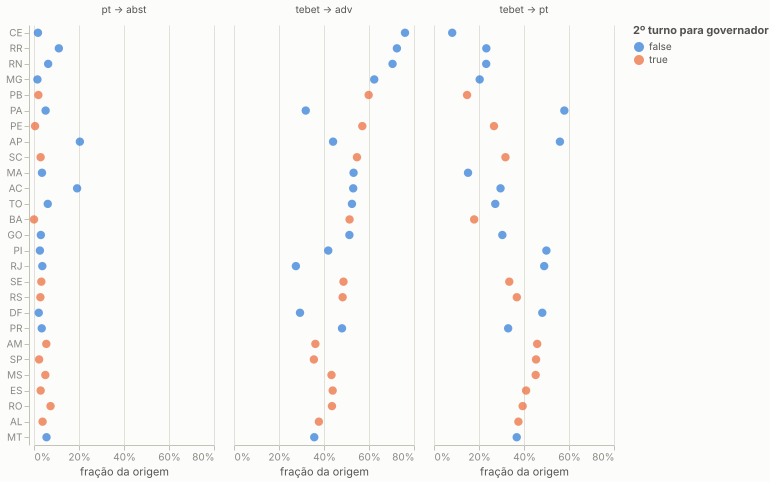

In [5]:
por_uf = (
    matriz.filter((pl.col("uf") != "BR") & pl.col("origem").is_in(["pt", "tebet"]))
    .with_columns(linha=pl.col("origem") + " → " + pl.col("destino"))
    .filter(pl.col("linha").is_in(["pt → abst", "tebet → pt", "tebet → adv"]))
    .join(governador.filter(pl.col("ano") == 2022).select("uf", "tem_2t"), on="uf")
    .with_columns(
        governador=pl.when("tem_2t").then(pl.lit("com 2º turno")).otherwise(pl.lit("sem 2º turno"))
    )
)
resultados.grafico(
    live,
    "G2_heterogeneidade_uf",
    alt.Chart(por_uf)
    .mark_point(filled=True, size=70)
    .encode(
        y=alt.Y("uf:N", sort=alt.EncodingSortField("b", op="max", order="descending"), title=None),
        x=alt.X("b:Q", title="fração da origem", axis=alt.Axis(format="%")),
        color=alt.Color(
            "tem_2t:N", title="2º turno para governador", scale=alt.Scale(range=SERIES[:2])
        ),
        tooltip=[
            "uf",
            "linha",
            alt.Tooltip("b:Q", format=".1%"),
            alt.Tooltip("ic_inf:Q", format=".1%"),
            alt.Tooltip("ic_sup:Q", format=".1%"),
        ],
    )
    .properties(width=180, height=420)
    .facet(column=alt.Column("linha:N", title=None)),
)

**O que observar:** as linhas dos finalistas variam pouco entre UFs; as de origens pequenas (Tebet no Nordeste, por exemplo) variam muito, porque poucos votos de origem por UF deixam a estimativa ruidosa. O nacional pondera cada UF pelos votos da origem e é dominado pelos estados grandes. A base de Lula que não votou no 2º turno (pt → abst) é maior em AP, AC e RR.

In [6]:
(
    cenarios.with_columns((pl.col("margem", "ic_inf", "ic_sup") / 1e6).round(2)),
    efeito.with_columns((pl.col("votos_1t", "saldo_2t", "efeito") / 1e6).round(3)).sort("efeito"),
)

(shape: (4, 4)
 ┌──────────────┬────────┬────────┬────────┐
 │ cenario      ┆ margem ┆ ic_inf ┆ ic_sup │
 │ ---          ┆ ---    ┆ ---    ┆ ---    │
 │ str          ┆ f64    ┆ f64    ┆ f64    │
 ╞══════════════╪════════╪════════╪════════╡
 │ perfil       ┆ -7.57  ┆ -7.86  ┆ -7.17  │
 │ como_tebet   ┆ -6.15  ┆ -6.44  ┆ -5.85  │
 │ como_ciro    ┆ -5.66  ┆ -5.95  ┆ -5.46  │
 │ como_direita ┆ -8.46  ┆ -8.81  ┆ -7.89  │
 └──────────────┴────────┴────────┴────────┘,
 shape: (10, 4)
 ┌──────────┬──────────┬──────────┬────────┐
 │ origem   ┆ votos_1t ┆ saldo_2t ┆ efeito │
 │ ---      ┆ ---      ┆ ---      ┆ ---    │
 │ str      ┆ f64      ┆ f64      ┆ f64    │
 ╞══════════╪══════════╪══════════╪════════╡
 │ pt       ┆ 53.722   ┆ 51.738   ┆ -1.984 │
 │ renan    ┆ 2.667    ┆ -0.993   ┆ -0.993 │
 │ caiado   ┆ 2.6      ┆ -0.818   ┆ -0.818 │
 │ abst     ┆ 32.895   ┆ -0.598   ┆ -0.598 │
 │ bn       ┆ 5.964    ┆ -0.563   ┆ -0.563 │
 │ cury     ┆ 3.439    ┆ -0.388   ┆ -0.388 │
 │ zema     ┆ 0.323    

**O que observar:** os quatro cenários dão Flávio à frente por 5,7 a 8,5 milhões. A maior parcela
isolada é a base de Lula que não volta no 2º turno, seguida por Renan e Caiado. O IC é estreito
porque mede só o erro de estimação; a incerteza de verdade é se 2026 repete 2022.

## G3 · Comparecimento

Reserva líquida e rendimento por ponto de comparecimento nos municípios onde Lula lidera, e os
municípios que mais rendem.

In [7]:
m["G3"], m["G3b"]

({'BR': {'nao_votou_mi': 32.894899,
   'reserva_mi': -1.1138944057052107,
   'reserva_lula_mi': 3.6563476063173312,
   'rendimento_pp_lula_mil': 186.68307271326017,
   'perdidos_mi': 0.7238109328703985,
   'perdidos_onde_lula_lidera_mi': -0.18049396347164534},
  'locais': {'casados': 0.7466600061645073},
  'licao_2022': {'beta': -0.009578709893215165,
   'ic_inf': -0.012523909534400014,
   'ic_sup': -0.0066335102520303155,
   'p': 1.966602436453968e-10,
   'n': 471010}},
 {'2022': {'adv': {'sem_governador': {'abst': 0.0009186207850702034,
     'ufs': 15},
    'com_governador': {'abst': 2.2492023915001407e-18, 'ufs': 12}},
   'pt': {'sem_governador': {'abst': 0.033539428172310745, 'ufs': 15},
    'com_governador': {'abst': 0.019825158832501213, 'ufs': 12}}},
  '2026': {'ufs_com_governador': 7,
   'votos_lula_sem_governador_mi': 45.679737}})

In [8]:
top = (
    reserva_mun.join(municipios, on="cd_ibge")
    .filter(pl.col("p_lula") > 0.5)
    .sort("rendimento_pp", descending=True)
    .head(25)
    .select(
        "nome",
        "uf",
        "aptos",
        pl.col("p_lula").round(3),
        pl.col("abstencao").round(3),
        pl.col("rendimento_pp").round(0),
        pl.col("perdidos").round(0),
    )
)
top

nome,uf,aptos,p_lula,abstencao,rendimento_pp,perdidos
str,str,i64,f64,f64,f64,f64
"""Salvador""","""BA""",1955479,0.707,0.201,8099.0,79396.0
"""São Paulo""","""SP""",9145124,0.525,0.234,4587.0,226932.0
"""Fortaleza""","""CE""",1795713,0.576,0.13,2736.0,-51048.0
"""Recife""","""PE""",1230407,0.59,0.159,2222.0,31897.0
"""Teresina""","""PI""",592974,0.66,0.149,1902.0,-5281.0
…,…,…,…,…,…,…
"""Caxias""","""MA""",113420,0.723,0.202,506.0,435.0
"""Timon""","""MA""",124767,0.702,0.156,504.0,-993.0
"""Itapipoca""","""CE""",103228,0.741,0.135,498.0,-2069.0


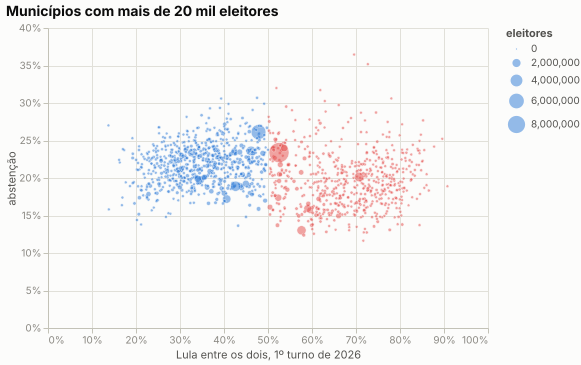

In [9]:
resultados.grafico(
    live,
    "G3_rendimento_vs_lula",
    alt.Chart(
        reserva_mun.filter(pl.col("aptos") > 20_000).select(
            "uf", "aptos", "p_lula", "abstencao", "rendimento_pp"
        )
    )
    .mark_circle(opacity=0.5, stroke="#fcfcfb", strokeWidth=0.5)
    .encode(
        x=alt.X(
            "p_lula:Q", title="Lula entre os dois, 1º turno de 2026", axis=alt.Axis(format="%")
        ),
        y=alt.Y("abstencao:Q", title="abstenção", axis=alt.Axis(format="%")),
        size=alt.Size("aptos:Q", title="eleitores", scale=alt.Scale(range=[8, 400])),
        color=alt.condition(
            "datum.p_lula > 0.5", alt.value(DIVERGENTE["pt"]), alt.value(DIVERGENTE["adversario"])
        ),
        tooltip=[
            "uf",
            "aptos",
            alt.Tooltip("p_lula:Q", format=".1%"),
            alt.Tooltip("abstencao:Q", format=".1%"),
            alt.Tooltip("rendimento_pp:Q", format="+,.0f"),
        ],
    )
    .properties(width=440, height=300, title="Municípios com mais de 20 mil eleitores"),
)

## G4 · Ex-eleitores (2º turno de 2022 → 1º de 2026)

In [10]:
m["G4"]

{'componentes_mi': {'delta': -6.470943,
  'eleitorado': 0.8788909242832765,
  'comparecimento': -0.10901319979933415,
  'validos': -0.14787301047739526,
  'fatia': -7.092947714006543},
 'fatia_mil': {'5_mil': -343.74060126032,
  '5_10_mil': -608.2563531715866,
  '10_20_mil': -941.3925092341595,
  '20_50_mil': -1275.2806416140963,
  '50_100_mil': -883.288711569347,
  '100_500_mil': -1544.921902659577,
  '500_mil': -1496.0669944974566}}

## G5 · Quem se moveu entre os turnos (exploratória)

Efeito de 1 desvio-padrão de cada característica sobre o Δ logit do PT do 1º para o 2º turno, com
efeito fixo de UF. Não tem veredito.

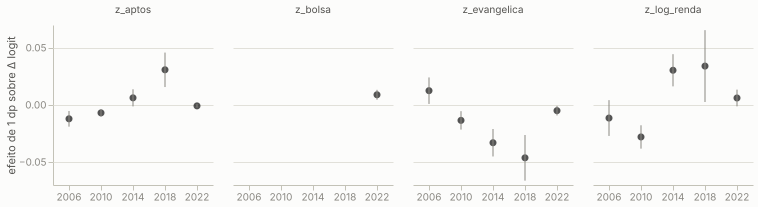

In [11]:
g5 = pl.DataFrame(
    [{"termo": t, "ano": a, **v} for t, anos in m["G5"].items() for a, v in anos.items()]
)
resultados.grafico(
    live,
    "G5_coeficientes",
    alt.Chart(g5)
    .encode(
        x=alt.X("ano:N", title=None, axis=alt.Axis(labelAngle=0)),
        y=alt.Y("coef:Q", title="efeito de 1 dp sobre Δ logit"),
    )
    .mark_point(filled=True, size=50, color=TINTA["primaria"])
    + alt.Chart(g5)
    .mark_rule(color=TINTA["apagada"])
    .encode(x="ano:N", y="ic_inf:Q", y2="ic_sup:Q"),
).properties(width=160, height=160).facet(facet=alt.Facet("termo:N", title=None), columns=4)

## Perguntas que ficam

- A base que falta (G3b) é região ou disputa local? Separar exige mais eleições (2014 e 2018 têm
  as mesmas informações) e registro próprio.
- Os cruzamentos das pesquisas (G6) dizem o mesmo que a matriz de 2022 sobre os eleitores de
  Tebet e Ciro? Se não, qual dos dois erra?
- Depois de 25/10: a B1 mede a matriz de 2026 com o mesmo estimador, e cada faixa acima é
  conferida.

In [12]:
live.end()